In [1]:
# we need it in all codes
import numpy as np 
import math
import matplotlib.pyplot as plt

from PIL import Image
import scipy.sparse
from scipy.sparse import csr_matrix
# see functions here
# https://numpy.org/doc/stable/reference/generated/numpy.exp.html
# https://numpy.org/doc/stable/reference/routines.array-manipulation.html
#

# basic vector and matrix operations
# general principle: we do not have to write functions for everything
# moreover, built-in vectorized operations are rather fast


0.8017328753190036 4.026118626930203


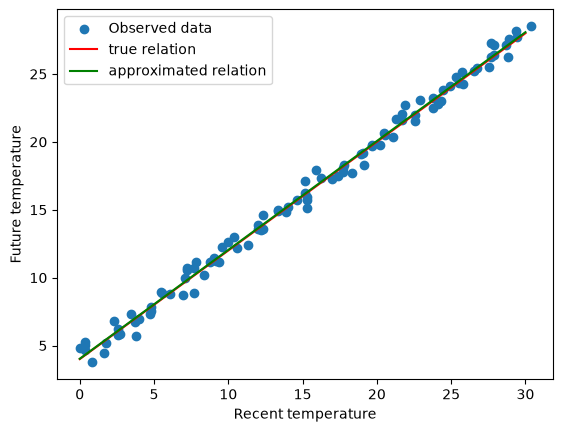

In [ ]:
#An example: our observed temperature is poluted with random errors (noise).
#We want to find the "true relation" between today's temperature and tomorrows
#For this dummny example we assume T_tomorrow = 0.8 T_today +4. We want to find this relation through the observed data.
np.random.seed(1)

# exact recent temperatures, sample of size 100
T_today = np.linspace(0,30, 100)
T_tomorrow = 0.8 * T_today + 4

#Generating errors: from the normal distribution so use np.random.normal
error_1 = np.random.normal(0,0.5, size = 100)
error_2 = np.random.normal(0,0.5, size = 100)
# exact physical relation
today_obs = T_today + error_1
tomorrow_obs = T_tomorrow + error_2

#Fit a simple model:
coeff = np.polyfit(today_obs, tomorrow_obs, 1)

a, b = coeff

print(a, b)


# what we actually observe
plt.scatter (today_obs, tomorrow_obs, label = 'Observed data')
plt.plot (T_today, T_tomorrow, color = 'red', label ='true relation')
plt.plot (T_today, a * T_today + b, color = 'green', label = "approximated relation")
plt.xlabel("Recent temperature")
plt.ylabel("Future temperature")
plt.legend()
plt.show()




# GENERATING RANDOM NUMBERS

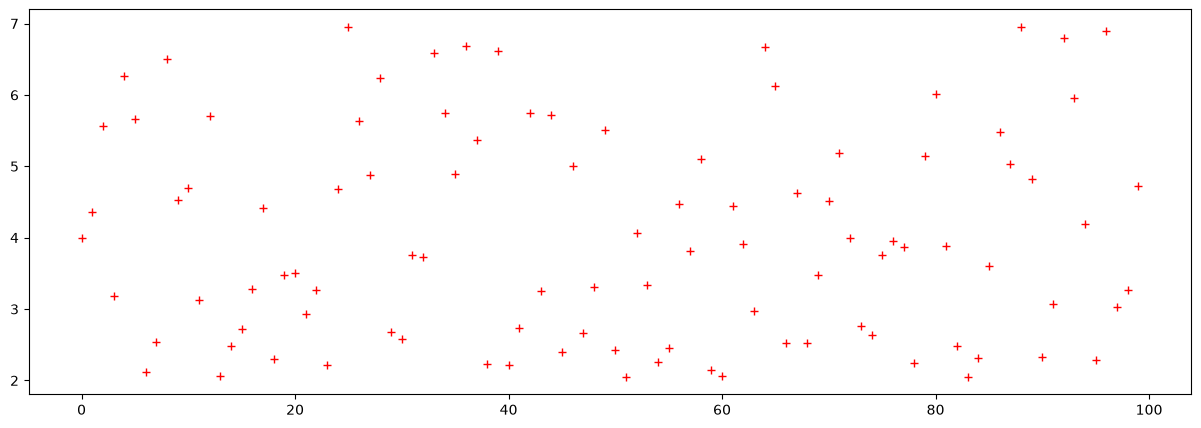

In [3]:
# Uniformly distributed numbers between 2 and 7
# We set the size of the figure.
plt.rcParams["figure.figsize"] = (15,5)
# We take 100 samples.
sample_few = np.random.uniform(2,7,100)
# x axis: the number of sample 
# y axis: the sample itself
plt.plot(sample_few, 'r+')
# It seems to be uniform but the figure is not very much informative.

(array([ 98.,  97., 104., 104.,  98., 100.,  95.,  98., 105., 101.]),
 array([2.00592234, 2.50527017, 3.00461801, 3.50396584, 4.00331368,
        4.50266151, 5.00200935, 5.50135718, 6.00070501, 6.50005285,
        6.99940068]),
 <BarContainer object of 10 artists>)

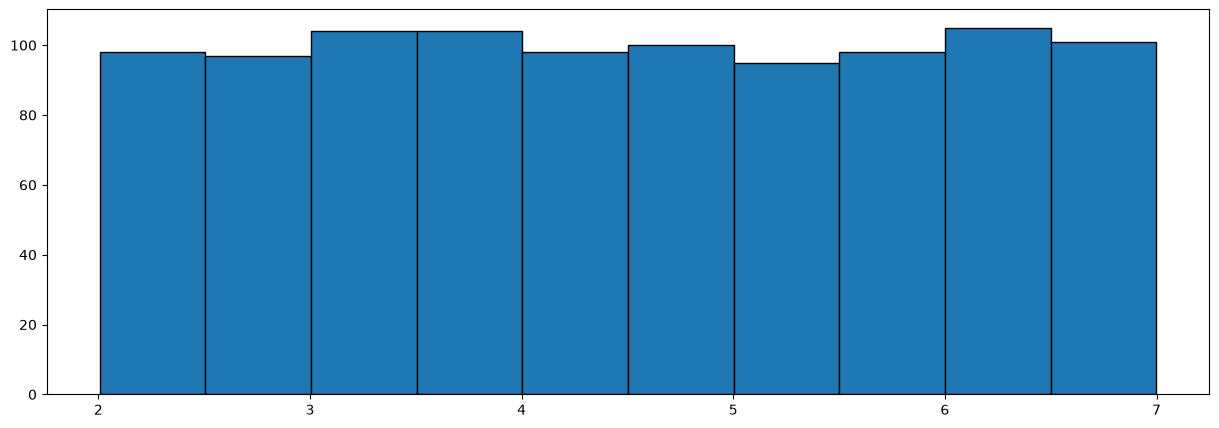

In [7]:
# uniformly distributed numbers between 2 and 7
# We take 1000 samples
sample = np.random.uniform(2,7,1000)
# A histogram will be shown: (use plt.hist!)
# 1. We take 10 subintervals of uniform lengths in (2.7) = (2, 2+5/10) (2.5, 3) ...
# 2. We count the number of samples in each subintervals.
# 3. These constant are shown in the subintervals.
plt.hist(sample, bins=10, ec = 'black')

#The sample seems to be uniform since our density function is constant. 
# Then P(a <x <b) = 1/5 * (b-a)
# is always the same
#for intervals (a,b) that have the same lenght 

(array([ 10.,  38.,  85., 183., 229., 226., 133.,  68.,  21.,   7.]),
 array([19.07411212, 20.2955359 , 21.51695968, 22.73838346, 23.95980724,
        25.18123103, 26.40265481, 27.62407859, 28.84550237, 30.06692616,
        31.28834994]),
 <BarContainer object of 10 artists>)

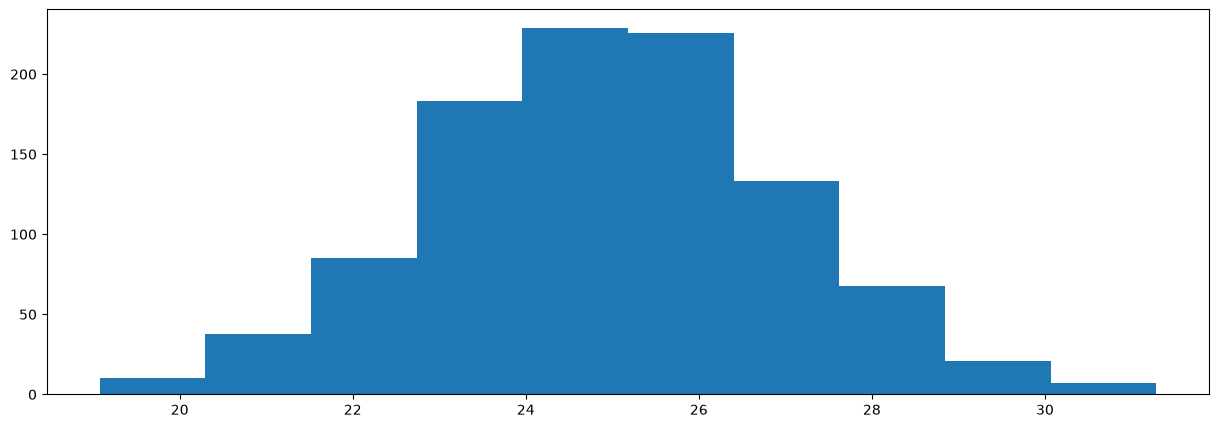

In [29]:
## CENTRAL LIMIT THEOREM IN ACTION!

# Take the sum of 2, 5 and 50 uniformly distributed vectors of length 1000
# and plot the histogram corresponding to these sums.

# Collect everything into (rows of) matrices
#np.random.rand generates numbers between (0 and 1)
#syntax: np.random.rand(n,m) generates random matrix n x m .
#Then A_2_rnd = [[ X_1,1 ..... X1,100
# #                 X_2,1 ..... X2,100]] each X_ij ~ U (0,1).

A_2_rnd = np.random.rand(2,1000) 
A_5_rnd = np.random.rand(5,1000)
A_50_rnd = np.random.rand(50,1000)

# We need to sum the rows of each matrix. Equivalently, each column of the matrix, say A_1, is a vector, sum all of the components of this vector
#do it for every column. This means np.sum(..., axis =0) yields a vector of size 1000. This vector represents adding up 1000 samples 
S2 = np.sum(A_2_rnd,axis=0)
S5 = np.sum(A_5_rnd,axis=0)
S50 = np.sum(A_50_rnd,axis=0)

plt.hist(S50, bins=10)
# They are indeed not uniform

1.5160754417762792
6.79334984934665


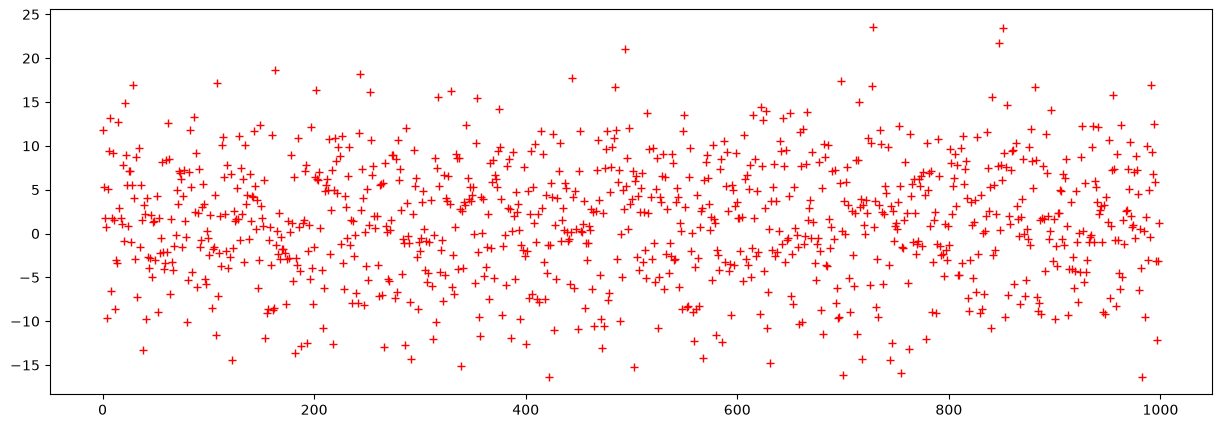

In [33]:
# Similar plot for the normal distribution N( mu= 2, sigma^2 = 7)
sample_normal = np.random.normal(2,7, 1000)
# The majority of the sample lie in the vicinity of the mean 2.
# Verify this experimentally and plot the result.
                ## LAW OF LARGE NUMBERS!
# HOW? check that the sample mean is close to 2:
sample_mean = sum(sample_normal)/1000

# Compute the empirical standard deviation. this is sqrt( 1/N* sum_i (x_i - x_mean)^2 )
sample_std_dev = math.sqrt(sum((sample_normal - sample_mean)**2)/1000)
# For the unbiased version one has to divide it by 999. This is because to compute the actual standard deviation
#of the sample, we need the true mean \mu, not the sample average. So our formula is a bit off, which gets compensated by the factor 1/N-1.
#The idea is that there are actually only N-1 deviations in the sample, since the last N deviation can be computed from the others, so there's only
#N degrees of freedom.

print(sample_mean)
print(sample_std_dev)
#Also, plot the sample
plt.plot(sample_normal, 'r+')
# By plotting a vector, x values are 1,2,3,...

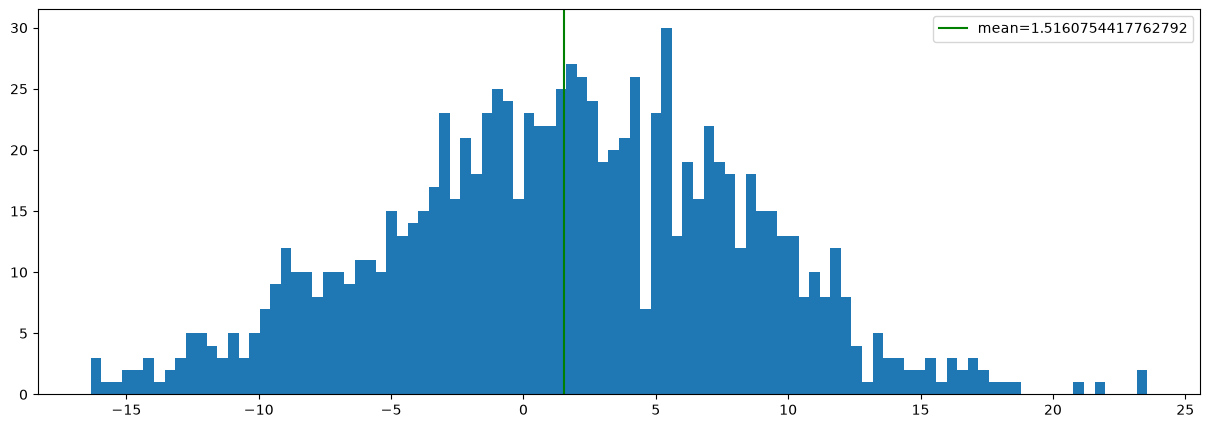

In [44]:
# It is not that much spectacular, plot rather a histogram
# You split the range of the data to equal segments and count the number of
# data points in the segments. This is shown in a histogram.
plt.hist(sample_normal, bins=100)
#Lets plot the mean:
plt.axvline(sample_mean, color='green', label=f'mean={sample_mean}')
plt.legend()
plt.show()
# Now you can track better the distribution of the sample.
# This can serve as an approximation of the probability density function.

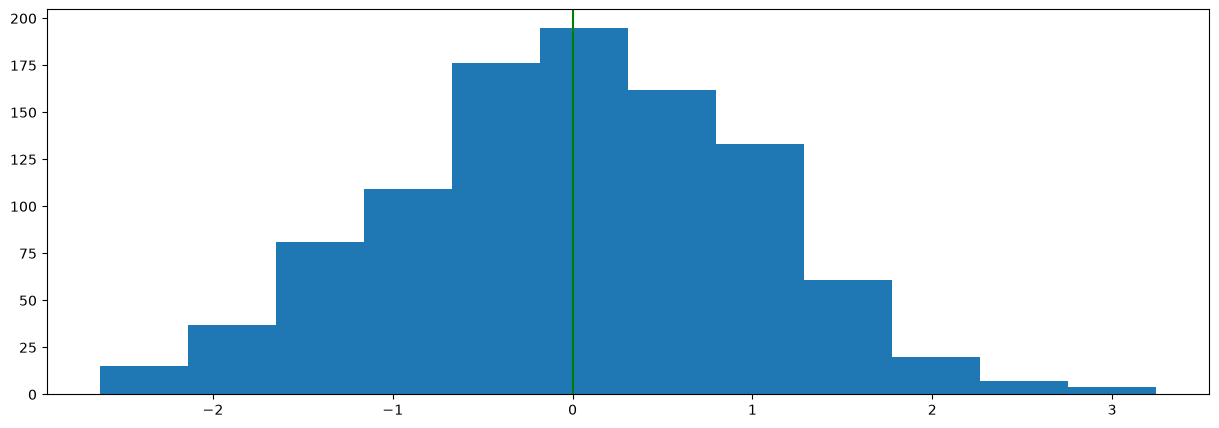

In [48]:
# Standardize everything: If you measure the same quantities in different units, minimization,
# optimization would give different results.
sample_normal_std = (sample_normal - sample_mean)/sample_std_dev
plt.hist(sample_normal_std, bins=12)
plt.axvline(np.sum(sample_normal_std)/1000, color='green')
plt.show()

# RANDOM CHOICE FROM GIVEN DATA

In [65]:
# We will study a number of observations s regarding forest fires. Each row corresponds to a forest fire event
# in Montensinho natural park, in Portugal. For each row ("sample"), the data set records 13 measurements.
# X, Y -> spatial coordinates where fire started.
# month, day -> date of when the fire happened.
# other measurements connected to likelihood of fires happening like temperature, wind speed, how dry the area was.
#Finally, it also measures the area that each fire took. This is what the original authors tried to predict based on the 
#other variables.

# We have a number of observations: these are collected into the rows of a matrix.
# Choose ten rows randomly.

# Source of the data: 
# https://archive.ics.uci.edu/dataset/162/forest+fires

import pandas as pd
#pd.read_csv will return a pandas dataframe. This is a table with rows and columns (with labels)
data = pd.read_csv('forestfires.csv')
print('='*27+'Forest fires data set'+ '='*27)
print(data)
print('='*75)

# Check its size    
print(f"The size of our data is:{data.shape}")


# Convert it to numpy array.
arr = data.to_numpy()

# Choose now 20 random row numbers. That is, choose 20 random samples
rand_row_numbers = np.random.randint(1, 517, size=20)
print("we choose randomly the following samples:")
print(rand_row_numbers)

# Take these rows.
random_data = arr[rand_row_numbers,:]

print("Our chosen data :")
print(random_data)


===========================Forest fires data set===========================
     X  Y month  day  FFMC    DMC     DC   ISI  temp  RH  wind  rain   area
0    7  5   mar  fri  86.2   26.2   94.3   5.1   8.2  51   6.7   0.0   0.00
1    7  4   oct  tue  90.6   35.4  669.1   6.7  18.0  33   0.9   0.0   0.00
2    7  4   oct  sat  90.6   43.7  686.9   6.7  14.6  33   1.3   0.0   0.00
3    8  6   mar  fri  91.7   33.3   77.5   9.0   8.3  97   4.0   0.2   0.00
4    8  6   mar  sun  89.3   51.3  102.2   9.6  11.4  99   1.8   0.0   0.00
..  .. ..   ...  ...   ...    ...    ...   ...   ...  ..   ...   ...    ...
512  4  3   aug  sun  81.6   56.7  665.6   1.9  27.8  32   2.7   0.0   6.44
513  2  4   aug  sun  81.6   56.7  665.6   1.9  21.9  71   5.8   0.0  54.29
514  7  4   aug  sun  81.6   56.7  665.6   1.9  21.2  70   6.7   0.0  11.16
515  1  4   aug  sat  94.4  146.0  614.7  11.3  25.6  42   4.0   0.0   0.00
516  6  3   nov  tue  79.5    3.0  106.7   1.1  11.8  31   4.5   0.0   0.00

[517 rows x

In [66]:
print(random_data.shape)

(20, 13)


In [ ]:
# Compute whether there is a dependence (covariance) between the 
# the strength of the wind and the burned area. 
#Wind is the 11th variable and area the last one (13th variable):
wind_data = arr[:,10]
area_data = arr[:,12]
#our array has a very general type (since some columns are strings), we must turn it into float
wind_data.astype(float) 
area_data.astype(float)
#they still need to be stored into new variables 

#Ok, then we will store these two observations from each sample in a matrix with 2 columns, column 1 will have the wind_data
#and column 2 the area_data:

X = np.stack((wind_data, area_data), axis=1) #adding a column, i.e., axis =1.
print(X.shape)
print("We will obtain the correlation matrix ∑ between wind and area ")
#This computes the correlation matrix between columns of matrix X. rowvar=False to treat each row as a sample!
print(np.corrcoef(X.astype(float), rowvar=False)) 
# Get also the temperature (9th variable) into the play and investigate whether 
# it has some an effect to the burned area.
temp_data = arr[:,8]
temp_data.astype(float)

print("We will obtain the correlation matrix ∑ between temperature and area")
Y = np.stack((temp_data, area_data), axis=1)
print(np.corrcoef(Y.astype(float), rowvar=False))
#We see very small linear correlation between the pairs. 

#What about temperature and wind speed??
print("We will obtain the correlation matrix ∑ between temperature and wind")
Z = np.stack((temp_data, wind_data), axis=1)
print(np.corrcoef(Z.astype(float), rowvar=False))
# The correlation is a bit more pronounced (and negative), it seems that higher temperatures and low wind speeds could be related.


(517, 2)
We will obtain the correlation matrix ∑ between wind and area 
[[1.         0.01231728]
 [0.01231728 1.        ]]
We will obtain the correlation matrix ∑ between temperature and area
[[1.         0.09784411]
 [0.09784411 1.        ]]
We will obtain the correlation matrix ∑ between temperature and wind
[[ 1.         -0.22711622]
 [-0.22711622  1.        ]]


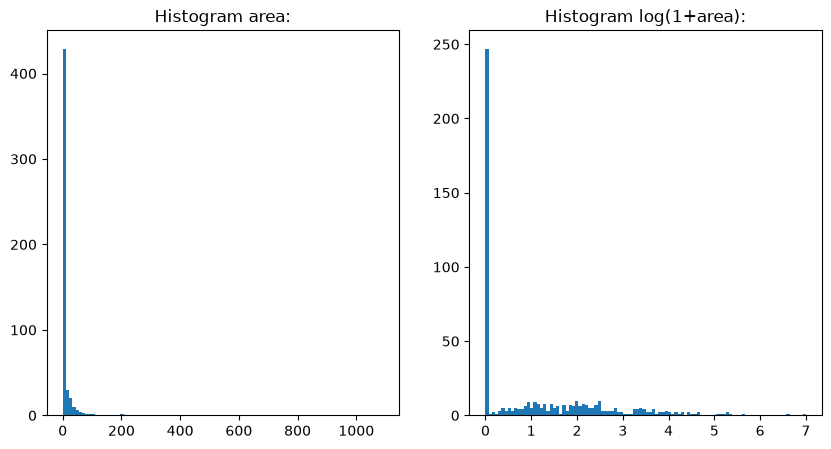

Let's check the correlation matrix now with this transformed data:
[[1.         0.06697349]
 [0.06697349 1.        ]]
Let's check the correlation matrix now with this transformed data:
[[1.         0.05348655]
 [0.05348655 1.        ]]


In [ ]:
# The researchers mentioned that for their model, they trained it using log(1+area). Why? because their samples
#  had a lot of very small fires (area < epsilon) and very few big ones. Hence if we plot the histogram we see a lot of values around zero
#and a huge right tail.  We want to get rid of this!
# That's why log is helpful. for small values of x log(1+x) ≈ x,
# and for large values log doesnt grow as fast.


# Let u see if the relations improve
area_log = np.log1p(area_data.astype(float)) #log1p does already log(1+x) 

#Let's see a histogram comparing area vs log(1+area)
fig, axis =plt.subplots(1,2, figsize=(10,5))
axis[0].hist(area_data.astype(float), bins =100)
axis[0].set_title("Histogram area:")
axis[1].hist(area_log, bins=100)
axis[1].set_title("Histogram log(1+area):")
plt.show()
X_log = np.stack((area_log,wind_data),axis =1)
print("Let's check the correlation matrix now with this transformed data:")
print(np.corrcoef(X_log.astype(float),rowvar= False))

Y_log = np.stack((area_log,temp_data),axis =1)
print("Let's check the correlation matrix now with this transformed data:")
print(np.corrcoef(Y_log.astype(float),rowvar= False))


